# Case 1 — EDA: Prediksi Magnitudo Gempa dari Waveform Stasiun Tunggal

Notebook eksplorasi untuk task regresi magnitudo dari 5 detik waveform 3-komponen
(1 detik sebelum P-wave, 4 detik sesudah) @ 200 Hz.

**Metrik: EB-TWMAE** (Event-Balanced Tail-Weighted MAE) — lebih kecil lebih baik.

Ringkasan naratif lengkap ada di [`penjelasan_case.md`](penjelasan_case.md).

> **Kernel:** pakai venv bersama `C:\Patrick\coding\.venv` (Python 3.11.6). Sudah berisi
> numpy/pandas/scipy/sklearn/lightgbm/xgboost/torch+CUDA. Jangan bikin venv baru, dan jangan
> pakai `python` polos dari PATH (itu Python 3.14 sistem yang kosong).

Struktur notebook:
1. Setup & load data
2. EDA metadata
3. Distribusi target & implikasi metrik
4. Rekonstruksi event (tidak ada `event_id` di dataset)
5. EDA waveform
6. Fitur fisika EEW (Pa / Pv / Pd)
7. Metrik EB-TWMAE & validasi GroupKFold
8. Baseline model & eksperimen weighting
9. Diagnosis error
10. Kesimpulan

---
## 1. Setup & Load Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import signal
from pathlib import Path
import time, warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

DATA = Path("seismic-dataset")
FS = 200            # sampling rate (Hz)
P_IDX = 200         # indeks P-wave arrival (1 detik * 200 Hz)
N_SAMP = 1000       # panjang window (5 detik)

print("data dir exists:", DATA.exists())

data dir exists: True


In [2]:
t0 = time.time()

train_meta   = pd.read_csv(DATA / "train" / "train_meta.csv")
train_labels = pd.read_csv(DATA / "train" / "train_labels.csv")
test_meta    = pd.read_csv(DATA / "test"  / "test_meta.csv")
sample_sub   = pd.read_csv(DATA / "sample_submission.csv")

train = train_meta.merge(train_labels, on="sample_id")

X_train = np.load(DATA / "train" / "train_waveforms.npy")
X_test  = np.load(DATA / "test"  / "test_waveforms.npy")

print(f"load: {time.time()-t0:.2f}s")
print("train meta :", train.shape)
print("test  meta :", test_meta.shape)
print("X_train    :", X_train.shape, X_train.dtype, f"{X_train.nbytes/1e6:.1f} MB")
print("X_test     :", X_test.shape,  X_test.dtype,  f"{X_test.nbytes/1e6:.1f} MB")

load: 0.08s
train meta : (10505, 6)
test  meta : (2300, 5)
X_train    : (10505, 1000, 3) float32 126.1 MB
X_test     : (2300, 1000, 3) float32 27.6 MB


Urutan baris CSV **sama persis** dengan urutan array `.npy` — jadi `X_train[i]`
berpasangan dengan `train.iloc[i]`. Tidak perlu join berbasis indeks.

In [3]:
train.head()

,sample_id,distance_km,depth_km,is_clipped,snr_db,magnitude
0,eq_026ba47eb87ad67b610b2c1d,80.225,17.15,False,39.07,5.3
1,eq_b5160fd8d811e713f2dcd98f,65.977,64.93,False,36.13,5.0
2,eq_31b75ce4b32a2d3adc587701,172.790,47.56,False,15.80,4.9
3,eq_3307aca2a70a0b55717962eb,137.244,11.54,False,31.20,5.1
4,eq_70ff949fd5bf41fcf2ef8d73,108.979,117.00,False,33.56,5.6


---
## 2. EDA Metadata

Cek kualitas data dulu sebelum apa-apa: null, duplikat, kebocoran ID antara train/test.

In [4]:
print("--- null values ---")
print("train:", train.isna().sum().to_dict())
print("test :", test_meta.isna().sum().to_dict())

print("\n--- duplikat sample_id ---")
print("train:", train.sample_id.duplicated().sum())
print("test :", test_meta.sample_id.duplicated().sum())

print("\n--- overlap ID train vs test ---")
print(len(set(train.sample_id) & set(test_meta.sample_id)))

print("\n--- NaN / Inf di waveform ---")
print("train:", np.isnan(X_train).sum(), np.isinf(X_train).sum())
print("test :", np.isnan(X_test).sum(),  np.isinf(X_test).sum())

--- null values ---
train: {'sample_id': 0, 'distance_km': 0, 'depth_km': 0, 'is_clipped': 0, 'snr_db': 0, 'magnitude': 0}
test : {'sample_id': 0, 'distance_km': 0, 'depth_km': 0, 'is_clipped': 0, 'snr_db': 0}

--- duplikat sample_id ---
train: 0
test : 0

--- overlap ID train vs test ---
0

--- NaN / Inf di waveform ---
train: 0 0
test : 0 0


Data **bersih total**: nol null, nol duplikat, nol overlap, nol NaN/Inf.
Praktis tidak ada pekerjaan cleaning — bisa langsung fokus ke feature engineering.

In [5]:
pcts = [.01, .05, .25, .5, .75, .95, .99]
num_cols = ["distance_km", "depth_km", "snr_db"]

print("=== TRAIN ===")
display(train[num_cols].describe(percentiles=pcts).T)
print("=== TEST ===")
display(test_meta[num_cols].describe(percentiles=pcts).T)

=== TRAIN ===


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
distance_km,10505.0,127.044677,46.658392,0.725,16.96444,40.3042,94.986,132.291,166.032,192.3524,198.31892,199.971
depth_km,10505.0,57.135186,62.783342,1.320,3.25000,7.2100,10.000,29.900,95.580,188.2000,271.21700,457.860
snr_db,10505.0,29.246505,11.103186,10.020,10.47000,12.0600,20.040,29.090,37.730,47.5600,53.46680,65.800


=== TEST ===


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
distance_km,2300.0,122.483086,51.316842,1.132,11.13654,28.6663,86.31925,132.3045,164.25975,192.3588,198.19075,199.801
depth_km,2300.0,58.038978,79.788201,1.181,5.00000,6.6290,10.00000,16.5735,76.20200,243.0000,375.00000,375.000
snr_db,2300.0,28.824378,11.085302,10.010,10.43890,12.0495,19.40250,28.7600,37.05500,47.4705,53.71180,72.620


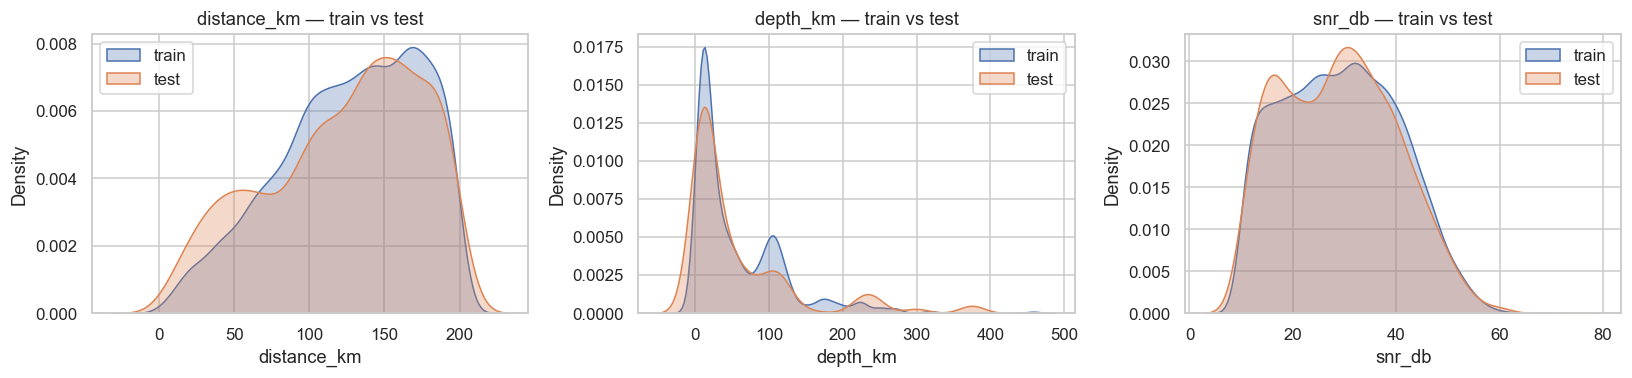

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, num_cols):
    sns.kdeplot(train[col], ax=ax, label="train", fill=True, alpha=.3)
    sns.kdeplot(test_meta[col], ax=ax, label="test", fill=True, alpha=.3)
    ax.set_title(f"{col} — train vs test")
    ax.legend()
plt.tight_layout(); plt.show()

Distribusi train dan test **saling tumpang tindih rapi** — tidak ada tanda
distribution shift yang perlu ditangani khusus.

Dua hal yang menonjol:
- `distance_km` dipotong keras di **200 km** (batas seleksi dataset, bukan fenomena alami).
- `depth_km` punya ekor panjang sampai ~458 km (gempa dalam / *deep-focus*).

In [7]:
print("--- is_clipped ---")
ct = pd.DataFrame({
    "train_n": train.is_clipped.value_counts(),
    "test_n":  test_meta.is_clipped.value_counts(),
})
ct["train_%"] = (ct.train_n / len(train) * 100).round(2)
ct["test_%"]  = (ct.test_n  / len(test_meta) * 100).round(2)
display(ct)

print("\nmagnitudo berdasar is_clipped:")
display(train.groupby("is_clipped").magnitude.describe())

--- is_clipped ---


,train_n,test_n,train_%,test_%
is_clipped,,,,
False,10329,2213,98.32,96.22
True,176,87,1.68,3.78



magnitudo berdasar is_clipped:


,count,mean,std,min,25%,50%,75%,max
is_clipped,,,,,,,,
False,10329.0,5.275554,0.386577,4.3,5.0,5.2,5.5,7.8
True,176.0,5.646023,0.538024,4.8,5.2,5.5,6.2,7.0


**Perhatian:** record clipped ada **3,8% di test** vs **1,7% di train** — dua kali lipat.

Record clipped juga punya magnitudo rata-rata jauh lebih tinggi (5,65 vs 5,28), masuk akal
karena gempa besar lebih mungkin membuat sensor saturasi. Konsekuensinya: untuk record ini
amplitudo puncak **tidak bisa dipercaya** (nilainya terpotong), padahal amplitudo adalah
fitur utama kita. `is_clipped` wajib jadi fitur eksplisit.

---
## 3. Distribusi Target & Implikasi Metrik

### Definisi metrik

```
1. Per gempa e:  MAE_e = mean(|y - y_hat|) atas semua record stasiun gempa itu
2. Skor akhir:   SUM(w_e * MAE_e) / SUM(w_e)
```

Bobot `w_e` ditentukan magnitudo sebenarnya: 1.0 (<5.5), 1.5 (5.5–6.0), 2.0 (6.0–6.5), 2.5 (>=6.5).

In [8]:
def mag_weight(m):
    '''Bobot tail metrik EB-TWMAE.'''
    m = np.asarray(m)
    return np.where(m < 5.5, 1.0, np.where(m < 6.0, 1.5, np.where(m < 6.5, 2.0, 2.5)))

BINS   = [-np.inf, 5.5, 6.0, 6.5, np.inf]
LABELS = ["<5.5", "5.5-6.0", "6.0-6.5", ">=6.5"]

train["mag_bin"] = pd.cut(train.magnitude, BINS, right=False, labels=LABELS)

print("range magnitudo:", train.magnitude.min(), "-", train.magnitude.max())
print("nilai unik     :", train.magnitude.nunique())

binstat = train.groupby("mag_bin", observed=True).agg(
    n_record=("magnitude", "size"),
).assign(
    pct=lambda d: (d.n_record / len(train) * 100).round(2),
    weight=[1.0, 1.5, 2.0, 2.5],
)
display(binstat)

range magnitudo: 4.3 - 7.8
nilai unik     : 32


,n_record,pct,weight
mag_bin,,,
<5.5,7518,71.57,1.0
5.5-6.0,2277,21.68,1.5
6.0-6.5,580,5.52,2.0
>=6.5,130,1.24,2.5


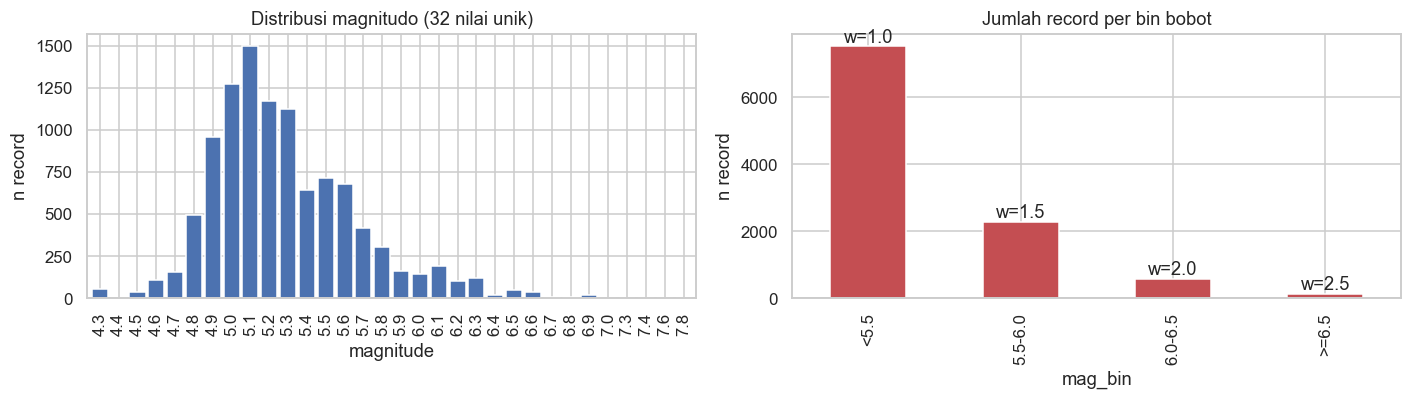

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

train.magnitude.value_counts().sort_index().plot(kind="bar", ax=axes[0], width=.85)
axes[0].set_title("Distribusi magnitudo (32 nilai unik)")
axes[0].set_xlabel("magnitude"); axes[0].set_ylabel("n record")

binstat.n_record.plot(kind="bar", ax=axes[1], color=sns.color_palette("deep")[3])
for i, (n, w) in enumerate(zip(binstat.n_record, binstat.weight)):
    axes[1].text(i, n, f"w={w}", ha="center", va="bottom")
axes[1].set_title("Jumlah record per bin bobot")
axes[1].set_ylabel("n record")

plt.tight_layout(); plt.show()

Ini **inti kesulitan soal**:

| Bin | Record | % | Bobot |
|---|---|---|---|
| M < 5.5 | 7.518 | 71,6% | 1.0 |
| 5.5–6.0 | 2.277 | 21,7% | 1.5 |
| 6.0–6.5 | 580 | 5,5% | 2.0 |
| **M >= 6.5** | **130** | **1,2%** | **2.5** |

Bin yang paling dihukum justru yang datanya paling sedikit. Model yang dilatih dengan
loss biasa akan mengoptimasi 72% data yang mudah, lalu kena penalti berat di 1,2% yang sulit.

---
## 4. Rekonstruksi Event

Metrik dihitung **per gempa**, tapi dataset **tidak menyediakan `event_id`**.
Setiap `sample_id` adalah satu record stasiun; beberapa record berasal dari gempa yang sama.

Kalau kita tidak merekonstruksi grouping event, dua hal rusak sekaligus:
- CV bocor (record gempa yang sama tersebar di train & valid fold)
- Sample weighting tidak bisa meniru event-balancing metrik

Kandidat kunci grouping: `depth_km` (sifat gempa, bukan stasiun) dikombinasi `magnitude`.

In [10]:
print("depth_km unik :", train.depth_km.nunique(), "dari", len(train), "record")

grp_depth = train.groupby("depth_km").size()
print("\nukuran grup by depth saja:")
print(grp_depth.describe())
print("grup terbesar:", grp_depth.max(), "record  (kemungkinan nilai default 10.0 km)")

n_mag = train.groupby("depth_km").magnitude.nunique()
print("\ndepth group dengan >1 magnitudo berbeda:", (n_mag > 1).sum(), "dari", len(n_mag))

depth_km unik : 750 dari 10505 record

ukuran grup by depth saja:
count     750.000000
mean       14.006667
std        61.198521
min         1.000000
25%         2.000000
50%         7.000000
75%        15.000000
max      1633.000000
dtype: float64
grup terbesar: 1633 record  (kemungkinan nilai default 10.0 km)

depth group dengan >1 magnitudo berbeda: 56 dari 750


`depth_km` saja **tidak cukup**: ada satu nilai depth dipakai 1.633 record — jelas bukan
satu gempa (kemungkinan nilai default 10,0 km yang dipakai banyak katalog seismik).
Kombinasikan dengan `magnitude` untuk mempersempit.

jumlah pseudo-event : 905
rata-rata stasiun   : 11.6

count    905.000000
mean      11.607735
std       22.661753
min        1.000000
25%        2.000000
50%        6.000000
75%       14.000000
max      401.000000
dtype: float64


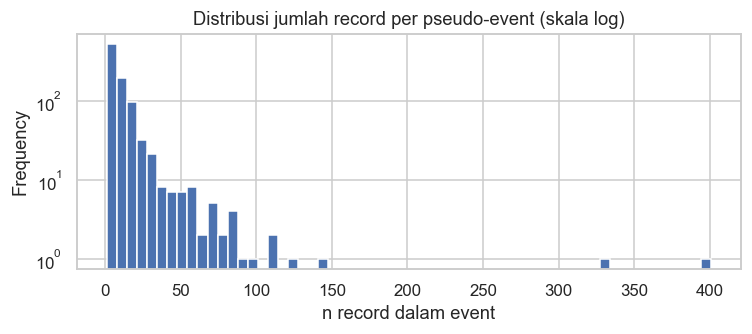


event dengan 1 record saja: 184
event terbesar           : 401 record


In [11]:
train["event_id"] = train.groupby(["depth_km", "magnitude"]).ngroup()

ev_size = train.groupby("event_id").size()
print("jumlah pseudo-event :", train.event_id.nunique())
print("rata-rata stasiun   : %.1f" % ev_size.mean())
print()
print(ev_size.describe())

fig, ax = plt.subplots(figsize=(7, 3.2))
ev_size.plot(kind="hist", bins=60, ax=ax)
ax.set_yscale("log")
ax.set_title("Distribusi jumlah record per pseudo-event (skala log)")
ax.set_xlabel("n record dalam event")
plt.tight_layout(); plt.show()

print("\nevent dengan 1 record saja:", (ev_size == 1).sum())
print("event terbesar           :", ev_size.max(), "record")

**905 pseudo-event** dari 10.505 record — rata-rata ~11,6 stasiun per gempa, tapi sangat
tidak seimbang (median 6, maksimum **401**, dan 184 event hanya punya 1 record).

Dua implikasi langsung:

1. **Ukuran sampel efektif jauh lebih kecil dari yang terlihat.** Kita punya 905 titik data
   independen, bukan 10.505. Ini membatasi seberapa kompleks model yang bisa dilatih tanpa
   overfitting — relevan sekali untuk keputusan CNN nanti.
2. **Satu event dengan 401 record bisa mendominasi gradien training**, padahal di metrik
   bobotnya sama dengan event 1-record. Harus dikoreksi lewat sample weight.

> **Caveat:** grouping ini heuristik, bukan ground truth. Kalau grouping sebenarnya berbeda,
> angka absolut EB-TWMAE bergeser — meski peringkat antar-metode kemungkinan tetap.
> Untuk test set grouping tidak bisa dihitung sama sekali (tidak ada label), jadi ini murni alat CV.

---
## 5. EDA Waveform

Pertanyaan pertama yang harus dijawab: **apakah waveform sudah dinormalisasi per-record?**

Ini menentukan segalanya. Amplitudo absolut adalah prediktor fisik utama magnitudo — kalau
data sudah dinormalisasi, informasi itu hilang dan strateginya berubah total.

In [12]:
peak = np.abs(X_train).max(axis=(1, 2))

print("amplitudo puncak per record:")
for p in [1, 25, 50, 75, 99]:
    print(f"  p{p:<3d} = {np.percentile(peak, p):.4g}")
print(f"  max  = {peak.max():.4g}")
print("\nrecord dengan puncak tepat 1.0 :", (peak == 1.0).sum())
print("global min / max               :", X_train.min(), X_train.max())

amplitudo puncak per record:
  p1   = 8.877e-06
  p25  = 0.0001072
  p50  = 0.0002693
  p75  = 0.000658
  p99  = 0.01021
  max  = 1.328

record dengan puncak tepat 1.0 : 0
global min / max               : -0.9428257 1.327526


**Tidak ada satupun record dengan puncak tepat 1.0**, dan amplitudo membentang 5 orde
magnitudo (8,9e-06 sampai 1,33). Data **tidak dinormalisasi per-record** — skala absolut
dipertahankan.

Ini kabar baik dan sekaligus peringatan: **jangan lakukan per-record normalization saat
preprocessing.** Itu akan membuang sinyal paling berharga di dataset ini.

Skala absolut (~1e-4 tipikal) konsisten dengan **akselerasi dalam m/s²**.

In [13]:
pre  = np.abs(X_train[:, :P_IDX, :]).max(axis=(1, 2))   # noise sebelum P
post = np.abs(X_train[:, P_IDX:, :]).max(axis=(1, 2))   # sinyal setelah P

print("median amplitudo pre-P  : %.4g" % np.median(pre))
print("median amplitudo post-P : %.4g" % np.median(post))
print("median rasio post/pre   : %.2fx" % np.median(post / (pre + 1e-12)))
print("\nrecord dengan pre >= post (mencurigakan):", (pre >= post).sum(),
      f"({(pre >= post).mean()*100:.1f}%)")

median amplitudo pre-P  : 2.909e-05
median amplitudo post-P : 0.0002693
median rasio post/pre   : 8.47x

record dengan pre >= post (mencurigakan): 66 (0.6%)


Struktur window **terkonfirmasi**: amplitudo setelah indeks 200 rata-rata **8,5x lebih besar**
dari window noise sebelumnya. P-wave arrival memang di detik ke-1 seperti dijanjikan soal.

Hanya 66 record (0,6%) yang tidak menunjukkan pola ini — kandidat record bermasalah atau
SNR sangat rendah. Jumlahnya kecil, tapi layak dicek ulang saat modeling.

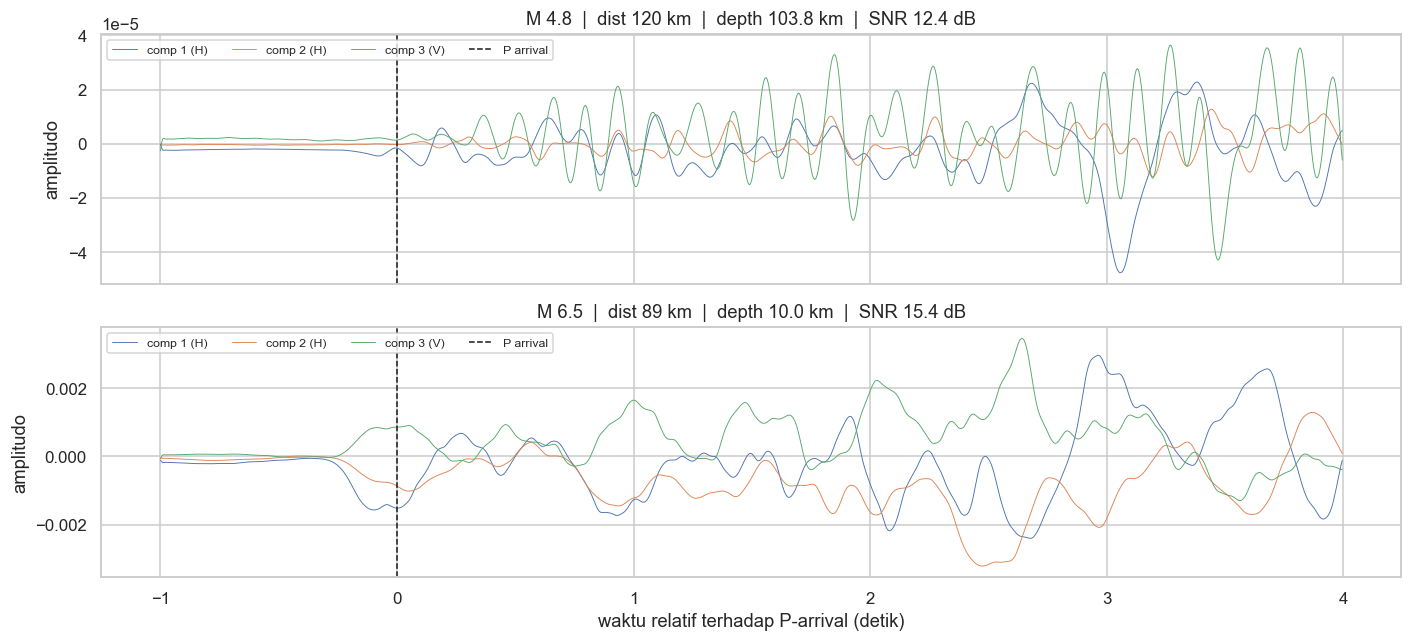

In [14]:
# contoh waveform: satu gempa kecil vs satu gempa besar
rng = np.random.default_rng(0)
idx_small = rng.choice(np.where(train.magnitude < 5.0)[0])
idx_large = rng.choice(np.where(train.magnitude >= 6.5)[0])

fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
tt = np.arange(N_SAMP) / FS - 1.0    # sumbu waktu relatif terhadap P (detik)

for ax, idx in zip(axes, [idx_small, idx_large]):
    r = train.iloc[idx]
    for c, name in enumerate(["comp 1 (H)", "comp 2 (H)", "comp 3 (V)"]):
        ax.plot(tt, X_train[idx, :, c], lw=.6, label=name)
    ax.axvline(0, color="k", ls="--", lw=1, label="P arrival")
    ax.set_title(f"M {r.magnitude}  |  dist {r.distance_km:.0f} km  "
                 f"|  depth {r.depth_km:.1f} km  |  SNR {r.snr_db:.1f} dB")
    ax.legend(loc="upper left", fontsize=8, ncol=4)
    ax.set_ylabel("amplitudo")

axes[-1].set_xlabel("waktu relatif terhadap P-arrival (detik)")
plt.tight_layout(); plt.show()

---
## 6. Fitur Fisika EEW: Pa / Pv / Pd

Literatur Earthquake Early Warning konsisten menunjukkan bahwa **peak displacement (Pd)**
di beberapa detik pertama setelah P adalah prediktor magnitudo terbaik — lebih baik dari
peak acceleration mentah. Alasannya fisis: konten frekuensi rendah membawa informasi
ukuran sumber, sementara frekuensi tinggi lebih mencerminkan lintasan dan kondisi lokal.

Kita uji klaim itu langsung di data ini:
- **Pa** = peak dari sinyal mentah (akselerasi)
- **Pv** = peak setelah 1x integrasi (kecepatan)
- **Pd** = peak setelah 2x integrasi (perpindahan)

High-pass Butterworth 0,075 Hz diterapkan sebelum tiap integrasi untuk menahan baseline drift
(integrasi memperkuat offset DC menjadi ramp yang mendominasi sinyal).

In [15]:
def highpass(a, fcut=0.075, order=2, fs=FS):
    b, aa = signal.butter(order, fcut / (fs / 2), btype="high")
    return signal.filtfilt(b, aa, a, axis=1)

def integrate_stack(X):
    '''Kembalikan (akselerasi, kecepatan, perpindahan).'''
    A = X.astype(np.float32)
    V = np.cumsum(highpass(A), axis=1) / FS
    D = np.cumsum(highpass(V), axis=1) / FS
    return A, V, D

t0 = time.time()
A, V, D = integrate_stack(X_train)
print(f"filter + integrasi ganda untuk {len(X_train)} record: {time.time()-t0:.2f}s")

filter + integrasi ganda untuk 10505 record: 1.46s


In [16]:
WINDOWS = [0.5, 1.0, 2.0, 3.0, 4.0]

def peak_in_window(W, seconds):
    n = int(seconds * FS)
    return np.abs(W[:, P_IDX:P_IDX + n, :]).max(axis=(1, 2))

feats = {}
for name, W in [("Pa", A), ("Pv", V), ("Pd", D)]:
    for sec in WINDOWS:
        feats[f"log{name}_{sec:g}s"] = np.log10(peak_in_window(W, sec) + 1e-15)

# tau_c: estimator periode dominan klasik (window 3 detik)
num = (V[:, P_IDX:P_IDX + 600, :] ** 2).sum(axis=1)
den = (D[:, P_IDX:P_IDX + 600, :] ** 2).sum(axis=1)
tau_c = 2 * np.pi * np.sqrt((den / (num + 1e-30)).mean(axis=1))
feats["log_tau_c"] = np.log10(tau_c + 1e-9)

F = pd.DataFrame(feats)
F["log_dist"]  = np.log10(train.distance_km.values + 1)
F["log_depth"] = np.log10(train.depth_km.values + 1)

y = train.magnitude.values
print("feature matrix:", F.shape)

feature matrix: (10505, 18)


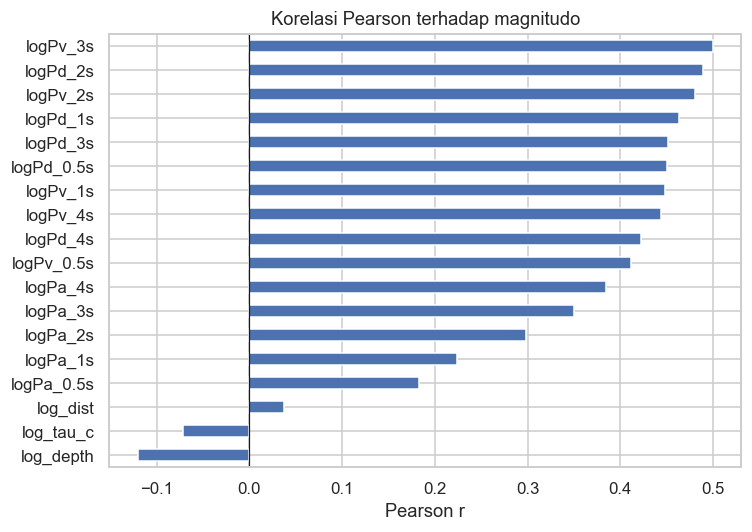

Pearson r terhadap magnitudo, per panjang window:


,Pa,Pv,Pd
0.5s,0.183,0.412,0.450
1s,0.224,0.448,0.463
2s,0.298,0.480,0.489
3s,0.350,0.500,0.451
4s,0.385,0.444,0.422


In [17]:
corr = pd.Series({c: np.corrcoef(F[c], y)[0, 1] for c in F.columns}).sort_values()

fig, ax = plt.subplots(figsize=(7, 5))
corr.plot(kind="barh", ax=ax)
ax.axvline(0, color="k", lw=.8)
ax.set_title("Korelasi Pearson terhadap magnitudo")
ax.set_xlabel("Pearson r")
plt.tight_layout(); plt.show()

# tabel Pa/Pv/Pd per window
tbl = pd.DataFrame(
    [[np.corrcoef(F[f"log{n}_{s:g}s"], y)[0, 1] for n in ["Pa", "Pv", "Pd"]] for s in WINDOWS],
    index=[f"{s:g}s" for s in WINDOWS], columns=["Pa", "Pv", "Pd"],
).round(3)
print("Pearson r terhadap magnitudo, per panjang window:")
display(tbl)

Tiga temuan konkret:

| Window | Pa | Pv | Pd |
|---|---|---|---|
| 0,5 s | 0,183 | 0,412 | **0,450** |
| 1 s | 0,224 | 0,448 | **0,463** |
| 2 s | 0,298 | 0,480 | **0,489** |
| 3 s | 0,350 | **0,500** | 0,451 |
| 4 s | 0,385 | 0,444 | 0,422 |

1. **Integrasi jelas membantu.** Pd dan Pv mengalahkan Pa telak di semua window pendek —
   persis seperti prediksi literatur EEW.
2. **Informasi datang cepat.** Pd pada 0,5 detik saja (r = 0,45) hampir sebaik window penuh.
3. **Pd justru menurun setelah 2 detik** — kemungkinan kontaminasi gelombang S atau
   akumulasi drift integrasi. Jangan asal pakai window terpanjang; ekstrak multi-window
   dan biarkan model yang memilih.

`tau_c` — estimator ukuran sumber klasik — ternyata **tidak berguna** di sini (r ~ −0,07).
Tidak perlu dikejar lebih jauh.

In [18]:
print("korelasi metadata mentah terhadap magnitudo (lemah semua):")
for c in num_cols:
    print(f"  {c:<14s} pearson={train[c].corr(train.magnitude):+.3f}  "
          f"spearman={train[c].corr(train.magnitude, method='spearman'):+.3f}")

print("\nkoreksi jarak pada Pd (amplitudo meluruh terhadap jarak -> harus di-detrend):")
for sec in [1, 2, 3, 4]:
    combo = F[f"logPd_{sec}s"] + 1.0 * F.log_dist
    print(f"  logPd_{sec}s + log_dist  ->  r = {np.corrcoef(combo, y)[0,1]:.3f}")

korelasi metadata mentah terhadap magnitudo (lemah semua):
  distance_km    pearson=+0.042  spearman=+0.052
  depth_km       pearson=-0.031  spearman=-0.159
  snr_db         pearson=-0.154  spearman=-0.125

koreksi jarak pada Pd (amplitudo meluruh terhadap jarak -> harus di-detrend):
  logPd_1s + log_dist  ->  r = 0.523
  logPd_2s + log_dist  ->  r = 0.551
  logPd_3s + log_dist  ->  r = 0.509
  logPd_4s + log_dist  ->  r = 0.477


Metadata mentah hampir tidak berkorelasi dengan magnitudo (|r| < 0,16 semuanya) — tapi
`distance_km` tetap **sangat penting sebagai variabel koreksi**: menggabungkan `log_dist`
dengan Pd menaikkan korelasi dari 0,489 → **0,551**.

Ini contoh klasik fitur yang lemah sendirian tapi kuat sebagai interaksi. Layak dimasukkan
secara eksplisit supaya model tidak perlu menemukan relasi ini dari nol.

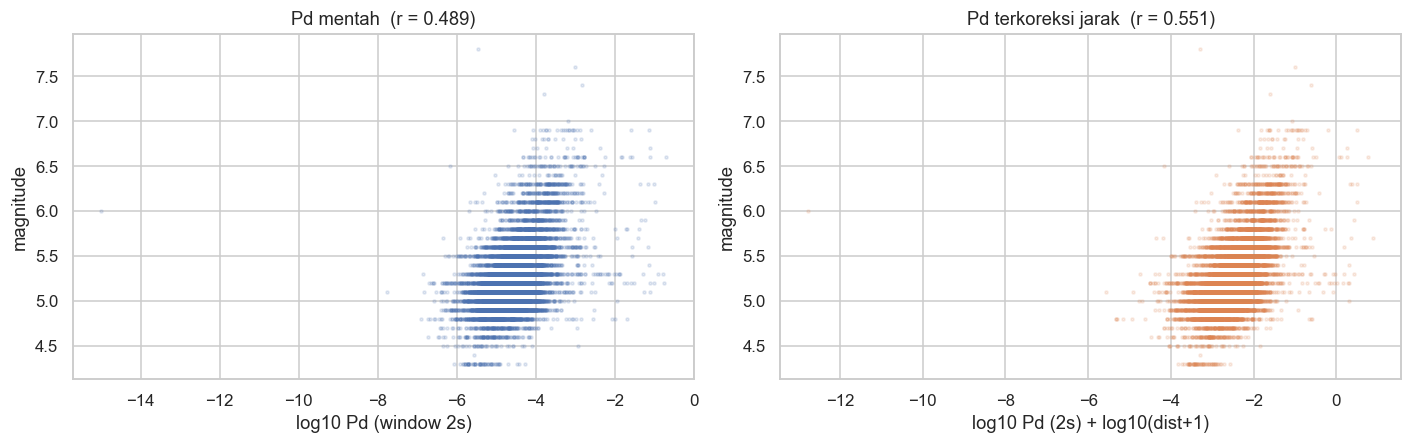

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

axes[0].scatter(F.logPd_2s, y, s=4, alpha=.15)
axes[0].set_xlabel("log10 Pd (window 2s)"); axes[0].set_ylabel("magnitude")
axes[0].set_title(f"Pd mentah  (r = {np.corrcoef(F.logPd_2s, y)[0,1]:.3f})")

combo = F.logPd_2s + F.log_dist
axes[1].scatter(combo, y, s=4, alpha=.15, color=sns.color_palette("deep")[1])
axes[1].set_xlabel("log10 Pd (2s) + log10(dist+1)"); axes[1].set_ylabel("magnitude")
axes[1].set_title(f"Pd terkoreksi jarak  (r = {np.corrcoef(combo, y)[0,1]:.3f})")

plt.tight_layout(); plt.show()

---
## 7. Metrik EB-TWMAE & Validasi GroupKFold

Implementasi metrik harus tepat — kalau salah, semua keputusan setelahnya ikut salah.
Perhatikan urutan operasi: rata-rata **per event dulu**, baru pembobotan.

In [20]:
def eb_twmae(y_true, y_pred, event_id):
    '''Event-Balanced Tail-Weighted MAE. Lebih kecil lebih baik.'''
    df = pd.DataFrame({"y": y_true, "p": y_pred, "e": event_id})
    g = df.groupby("e").apply(
        lambda x: pd.Series({"mae": np.abs(x.y - x.p).mean(), "m": x.y.iloc[0]}),
        include_groups=False,
    )
    w = mag_weight(g.m.values)
    return float((w * g.mae.values).sum() / w.sum())

ev = train.event_id.values

# sanity check: prediksi sempurna -> 0
assert abs(eb_twmae(y, y, ev)) < 1e-12
print("sanity check lolos (prediksi sempurna -> 0.0)")

print("\nbaseline konstan:")
for c in [5.2, 5.4, float(np.median(y)), float(y.mean())]:
    pred = np.full_like(y, c)
    print(f"  konstan {c:.2f}  EB-TWMAE = {eb_twmae(y, pred, ev):.4f}"
          f"   (MAE per-record = {np.abs(y - pred).mean():.4f})")

sanity check lolos (prediksi sempurna -> 0.0)

baseline konstan:


  konstan 5.20  EB-TWMAE = 0.4670   (MAE per-record = 0.2932)
  konstan 5.40  EB-TWMAE = 0.4452   (MAE per-record = 0.3336)


  konstan 5.20  EB-TWMAE = 0.4670   (MAE per-record = 0.2932)


  konstan 5.28  EB-TWMAE = 0.4527   (MAE per-record = 0.3010)


Perhatikan divergensi ini — ini bukti bahwa metrik dan MAE biasa mengarah ke **optimum yang berbeda**:

| Konstanta | EB-TWMAE | MAE per-record |
|---|---|---|
| 5.20 (isi `sample_submission`) | 0,4670 | **0,2932** (terbaik) |
| 5.40 | **0,4452** (terbaik) | 0,3336 |

Konstanta terbaik menurut MAE justru **bukan** yang terbaik menurut metrik lomba. Optimasi
MAE per-record adalah target yang salah — dan efeknya akan makin besar di model sungguhan.

In [21]:
from sklearn.model_selection import GroupKFold, KFold
from sklearn.ensemble import HistGradientBoostingRegressor

meta_feats = train[["distance_km", "depth_km", "snr_db"]].copy()
meta_feats["is_clipped"] = train.is_clipped.astype(int)

FEATS = pd.concat([meta_feats.reset_index(drop=True), F.reset_index(drop=True)], axis=1)
print("final feature matrix:", FEATS.shape)
print(list(FEATS.columns))

final feature matrix: (10505, 22)
['distance_km', 'depth_km', 'snr_db', 'is_clipped', 'logPa_0.5s', 'logPa_1s', 'logPa_2s', 'logPa_3s', 'logPa_4s', 'logPv_0.5s', 'logPv_1s', 'logPv_2s', 'logPv_3s', 'logPv_4s', 'logPd_0.5s', 'logPd_1s', 'logPd_2s', 'logPd_3s', 'logPd_4s', 'log_tau_c', 'log_dist', 'log_depth']


In [22]:
def run_cv(Xf, y, groups, sample_weight=None, loss="absolute_error",
           n_splits=5, seed=0, use_groups=True):
    '''OOF prediction dengan GroupKFold (atau KFold biasa untuk demo kebocoran).'''
    Xv = Xf.values if hasattr(Xf, "values") else Xf
    oof = np.zeros(len(y))
    splitter = (GroupKFold(n_splits=n_splits).split(Xv, y, groups)
                if use_groups else KFold(n_splits=n_splits, shuffle=True,
                                         random_state=seed).split(Xv))
    for tr_i, va_i in splitter:
        m = HistGradientBoostingRegressor(
            max_iter=400, learning_rate=.05, loss=loss, random_state=seed)
        m.fit(Xv[tr_i], y[tr_i],
              sample_weight=None if sample_weight is None else sample_weight[tr_i])
        oof[va_i] = m.predict(Xv[va_i])
    return oof

In [23]:
# Demonstrasi kebocoran: KFold biasa vs GroupKFold berbasis event
t0 = time.time()
oof_leaky = run_cv(FEATS, y, ev, use_groups=False)
oof_clean = run_cv(FEATS, y, ev, use_groups=True)

print(f"KFold biasa (BOCOR) : EB-TWMAE = {eb_twmae(y, oof_leaky, ev):.4f}")
print(f"GroupKFold (benar)  : EB-TWMAE = {eb_twmae(y, oof_clean, ev):.4f}")
print(f"\nselisih optimisme palsu: {eb_twmae(y, oof_clean, ev) - eb_twmae(y, oof_leaky, ev):.4f}")
print(f"({time.time()-t0:.0f}s)")

KFold biasa (BOCOR) : EB-TWMAE = 0.2654
GroupKFold (benar)  : EB-TWMAE = 0.2962



selisih optimisme palsu: 0.0308
(14s)


KFold biasa memberi skor yang **terlalu optimis** karena record dari gempa yang sama bocor
antara fold train dan valid — model bisa "menghafal" magnitudo lewat `depth_km` yang identik.

**Semua evaluasi setelah ini pakai `GroupKFold` berbasis `event_id`.**

---
## 8. Baseline Model & Eksperimen Weighting

Sekarang bagian yang paling berdampak. Kita uji dua hal terpisah:
1. Kontribusi masing-masing kelompok fitur (metadata vs fisika)
2. Pengaruh sample weighting yang **dicocokkan dengan struktur metrik**

In [24]:
results = {}
t0 = time.time()

feature_sets = {
    "metadata saja":     meta_feats,
    "fisika saja":       F,
    "metadata + fisika": FEATS,
}

for name, Xf in feature_sets.items():
    oof = run_cv(Xf, y, ev)
    results[name] = eb_twmae(y, oof, ev)
    print(f"{name:<20s} EB-TWMAE = {results[name]:.4f}   "
          f"MAE = {np.abs(y - oof).mean():.4f}")

oof_base = run_cv(FEATS, y, ev)
print(f"\n({time.time()-t0:.0f}s)")

metadata saja        EB-TWMAE = 0.4572   MAE = 0.3170


fisika saja          EB-TWMAE = 0.3061   MAE = 0.2270


metadata + fisika    EB-TWMAE = 0.2962   MAE = 0.2231



(22s)


**Metadata saja (0,4572) bahkan lebih buruk dari tebakan konstan terbaik (0,4452).**
Praktis seluruh sinyal ada di waveform — feature engineering waveform adalah pekerjaan utama,
bukan pengolahan metadata.

In [25]:
# Sample weighting yang meniru struktur metrik:
#   w(M)      -> meniru tail-weighting
#   / n_event -> meniru event-balancing (event 401-record tidak boleh dominasi gradien)
event_count = train.event_id.map(train.event_id.value_counts()).values

w_mag  = mag_weight(y)
w_full = w_mag / event_count

t0 = time.time()
oof_wmag = run_cv(FEATS, y, ev, sample_weight=w_mag)
oof_full = run_cv(FEATS, y, ev, sample_weight=w_full)
oof_l2   = run_cv(FEATS, y, ev, loss="squared_error")

print(f"tanpa weighting (L1)         : {eb_twmae(y, oof_base, ev):.4f}")
print(f"loss L2                      : {eb_twmae(y, oof_l2,   ev):.4f}")
print(f"bobot magnitudo saja         : {eb_twmae(y, oof_wmag, ev):.4f}")
print(f"bobot magnitudo / n_event    : {eb_twmae(y, oof_full, ev):.4f}   <-- terbaik")
print(f"\nperbaikan: {(1 - eb_twmae(y, oof_full, ev)/eb_twmae(y, oof_base, ev))*100:.1f}%")
print(f"({time.time()-t0:.0f}s)")

tanpa weighting (L1)         : 0.2962
loss L2                      : 0.2764


bobot magnitudo saja         : 0.2746
bobot magnitudo / n_event    : 0.2420   <-- terbaik



perbaikan: 18.3%
(46s)


### Ini temuan utama notebook

| Setup | EB-TWMAE |
|---|---|
| Tanpa weighting (L1) | 0,2962 |
| Loss L2 | 0,2764 |
| Bobot magnitudo saja | 0,2746 |
| **Bobot magnitudo / n_event** | **0,2420** |

Sample weighting saja memangkas error **18%** — tanpa menambah satupun fitur baru atau
mengubah arsitektur model. Ini rasio hasil-terhadap-effort terbaik di seluruh eksperimen,
dan harus dikerjakan sebelum optimasi apapun yang lain.

Loss L2 lebih buruk dari L1, konsisten dengan metrik yang berbasis MAE.

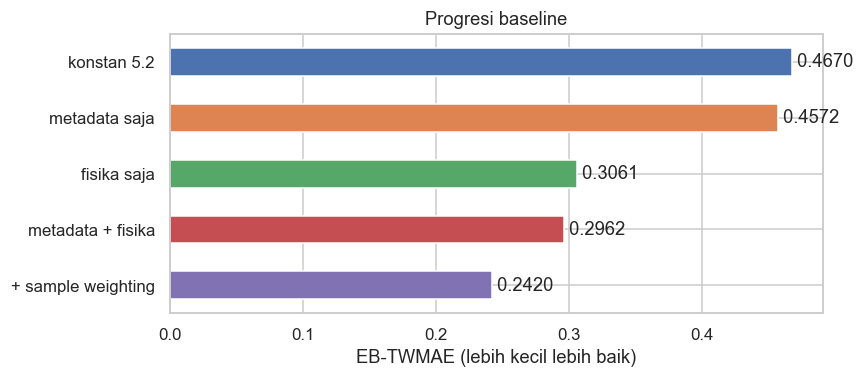

In [26]:
fig, ax = plt.subplots(figsize=(8, 3.6))
summary = pd.Series({
    "konstan 5.2":        eb_twmae(y, np.full_like(y, 5.2), ev),
    "metadata saja":      results["metadata saja"],
    "fisika saja":        results["fisika saja"],
    "metadata + fisika":  results["metadata + fisika"],
    "+ sample weighting": eb_twmae(y, oof_full, ev),
})
summary.plot(kind="barh", ax=ax, color=sns.color_palette("deep"))
for i, v in enumerate(summary):
    ax.text(v, i, f" {v:.4f}", va="center")
ax.set_xlabel("EB-TWMAE (lebih kecil lebih baik)")
ax.set_title("Progresi baseline")
ax.invert_yaxis()
plt.tight_layout(); plt.show()

---
## 9. Diagnosis Error

Di mana model masih salah, dan seberapa mahal kesalahan itu menurut metrik?

In [27]:
diag = train[["magnitude", "mag_bin", "distance_km", "snr_db", "is_clipped"]].copy()
diag["pred_base"] = oof_base
diag["pred_wt"]   = oof_full
diag["err_base"]  = np.abs(oof_base - y)
diag["err_wt"]    = np.abs(oof_full - y)

per_bin = diag.groupby("mag_bin", observed=True).agg(
    n=("magnitude", "size"),
    mae_base=("err_base", "mean"),
    mae_weighted=("err_wt", "mean"),
).round(3)
per_bin["bobot"] = [1.0, 1.5, 2.0, 2.5]
display(per_bin)

,n,mae_base,mae_weighted,bobot
mag_bin,,,,
<5.5,7518,0.182,0.204,1.0
5.5-6.0,2277,0.258,0.247,1.5
6.0-6.5,580,0.486,0.304,2.0
>=6.5,130,0.821,0.424,2.5


rentang prediksi vs kenyataan
  target sebenarnya   : 4.30 - 7.80
  tanpa weighting     : 4.69 - 6.42
  dengan weighting    : 4.79 - 6.95


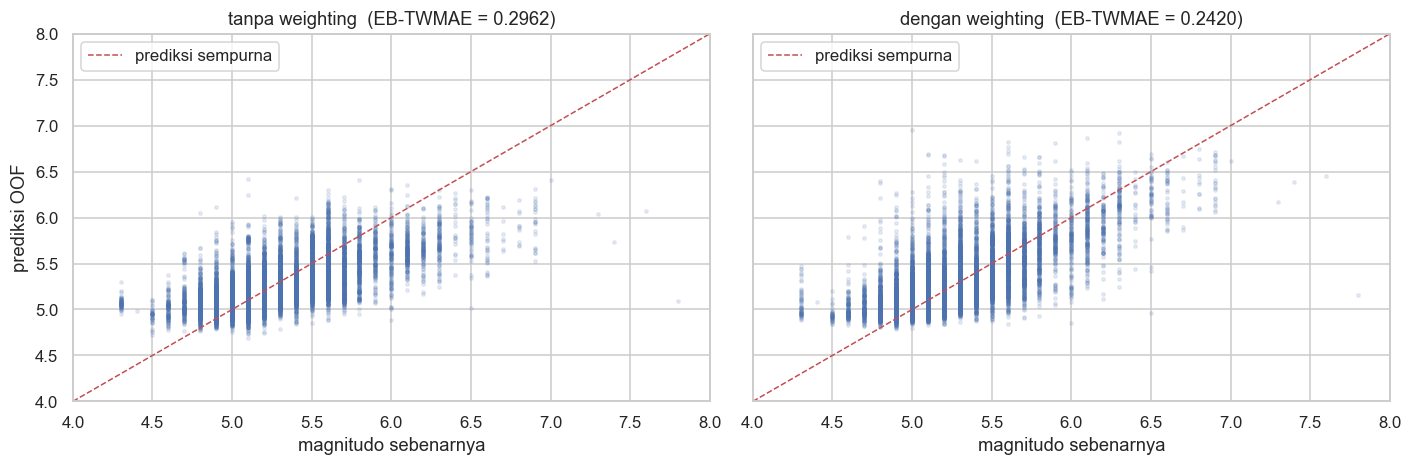

In [28]:
print("rentang prediksi vs kenyataan")
print(f"  target sebenarnya   : {y.min():.2f} - {y.max():.2f}")
print(f"  tanpa weighting     : {oof_base.min():.2f} - {oof_base.max():.2f}")
print(f"  dengan weighting    : {oof_full.min():.2f} - {oof_full.max():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (p, ttl) in zip(axes, [(oof_base, "tanpa weighting"), (oof_full, "dengan weighting")]):
    ax.scatter(y, p, s=5, alpha=.12)
    lo, hi = 4.0, 8.0
    ax.plot([lo, hi], [lo, hi], "r--", lw=1, label="prediksi sempurna")
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel("magnitudo sebenarnya"); ax.set_title(f"{ttl}  (EB-TWMAE = {eb_twmae(y, p, ev):.4f})")
    ax.legend()
axes[0].set_ylabel("prediksi OOF")
plt.tight_layout(); plt.show()

Pola **regression-to-the-mean** terlihat jelas: awan titik jauh lebih datar dari garis
diagonal. Model tanpa weighting tidak pernah memprediksi di atas **6,42** padahal target
mencapai **7,8** — ia tidak pernah berani menebak gempa besar.

Error per-bin menunjukkan biayanya:

| Bin | MAE (tanpa bobot) | Bobot |
|---|---|---|
| M < 5.5 | 0,182 | 1,0 |
| 5.5–6,0 | 0,258 | 1,5 |
| 6,0–6,5 | 0,486 | 2,0 |
| **M >= 6.5** | **0,821** | **2,5** |

Bin M >= 6.5 punya error **4,5x lebih besar** dari bin terkecil, lalu dikalikan bobot 2,5.
Hanya 1,2% data, tapi kontribusinya ke skor akhir sangat tidak proporsional.

Weighting memperbaiki ini secara alami — prediksi maksimum naik 6,42 → 6,95.

In [29]:
# Apakah kalibrasi ekspansi varians masih menambah setelah weighting?
print("faktor ekspansi alpha di sekitar mean prediksi:\n")
for label, p in [("tanpa weighting", oof_base), ("dengan weighting", oof_full)]:
    print(f"  {label}:")
    for a in [1.0, 1.1, 1.2, 1.3, 1.4]:
        pc = p.mean() + a * (p - p.mean())
        print(f"    alpha={a:.1f}  EB-TWMAE={eb_twmae(y, pc, ev):.4f}  pred_max={pc.max():.2f}")
    print()

faktor ekspansi alpha di sekitar mean prediksi:

  tanpa weighting:


    alpha=1.0  EB-TWMAE=0.2962  pred_max=6.42


    alpha=1.1  EB-TWMAE=0.2884  pred_max=6.53


    alpha=1.2  EB-TWMAE=0.2827  pred_max=6.65


    alpha=1.3  EB-TWMAE=0.2793  pred_max=6.76


    alpha=1.4  EB-TWMAE=0.2783  pred_max=6.88

  dengan weighting:
    alpha=1.0  EB-TWMAE=0.2420  pred_max=6.95


    alpha=1.1  EB-TWMAE=0.2401  pred_max=7.11


    alpha=1.2  EB-TWMAE=0.2431  pred_max=7.27


    alpha=1.3  EB-TWMAE=0.2516  pred_max=7.44


    alpha=1.4  EB-TWMAE=0.2653  pred_max=7.60



Hasilnya instruktif:

- **Tanpa weighting**: alpha = 1,3–1,4 memperbaiki 0,2962 → 0,2783. Kalibrasi memang menambal
  kompresi prediksi.
- **Dengan weighting**: alpha = 1,0 sudah optimal (0,2420); alpha = 1,2 justru sedikit memburuk.

Artinya sample weighting **sudah menangani kompresi dengan benar di level training**.
Kalibrasi post-hoc adalah tambalan untuk model yang tidak diberi bobot — bukan optimasi
tambahan yang bisa ditumpuk di atasnya. Jangan pakai keduanya sekaligus.

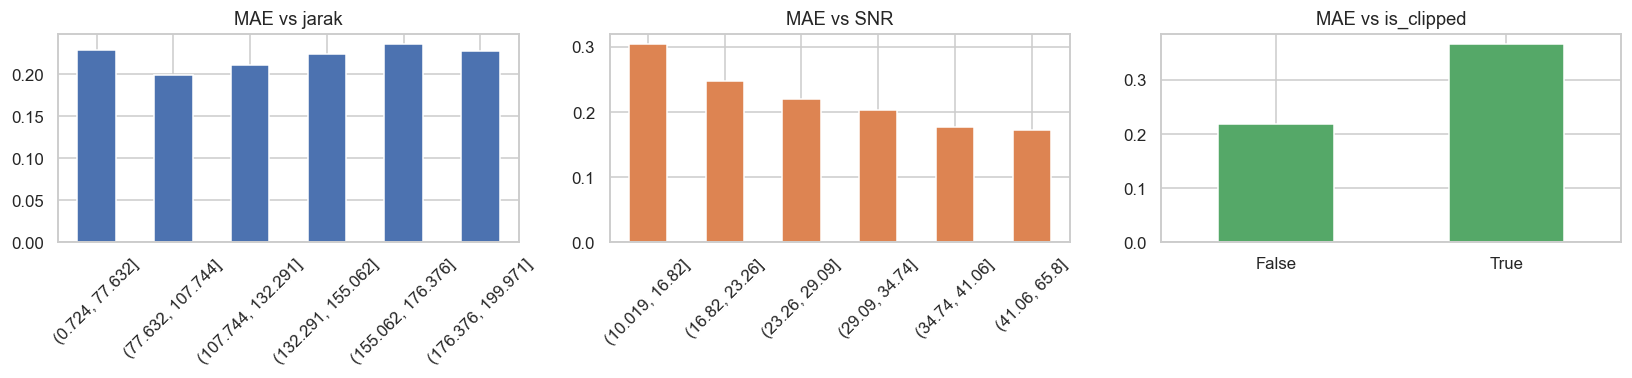

In [30]:
# Error terhadap kondisi record
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

diag["dist_bin"] = pd.qcut(diag.distance_km, 6)
diag.groupby("dist_bin", observed=True).err_wt.mean().plot(kind="bar", ax=axes[0])
axes[0].set_title("MAE vs jarak"); axes[0].set_xlabel(""); axes[0].tick_params(axis="x", rotation=45)

diag["snr_bin"] = pd.qcut(diag.snr_db, 6)
diag.groupby("snr_bin", observed=True).err_wt.mean().plot(kind="bar", ax=axes[1], color=sns.color_palette("deep")[1])
axes[1].set_title("MAE vs SNR"); axes[1].set_xlabel(""); axes[1].tick_params(axis="x", rotation=45)

diag.groupby("is_clipped").err_wt.mean().plot(kind="bar", ax=axes[2], color=sns.color_palette("deep")[2])
axes[2].set_title("MAE vs is_clipped"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=0)

plt.tight_layout(); plt.show()

---
## 10. Kesimpulan & Langkah Berikutnya

### Temuan utama

1. **Data bersih total** — nol null/NaN/duplikat. Tidak ada pekerjaan cleaning.
2. **Tidak ada `event_id`**, tapi `(depth_km, magnitude)` merekonstruksi ~905 pseudo-event.
   Ukuran sampel efektif adalah 905, bukan 10.505.
3. **Waveform tidak dinormalisasi** — skala amplitudo absolut dipertahankan.
   **Jangan normalisasi per-record**; itu membuang sinyal utama.
4. **Metadata mentah hampir tidak berguna sendirian** (bahkan kalah dari konstan terbaik),
   tapi `distance_km` penting sebagai variabel koreksi terhadap Pd (r: 0,489 → 0,551).
5. **Fitur Pd/Pv jauh mengalahkan Pa** — sesuai literatur EEW. Window pendek (0,5–2 s)
   sudah sangat informatif; Pd menurun setelah 2 detik.
6. **`tau_c` tidak berguna** di dataset ini (r ~ −0,07).
7. **Sample weighting `w(M) / n_event` memangkas error 18%** (0,2962 → 0,2420) —
   perbaikan terbesar dari perubahan paling murah.
8. **Kompresi prediksi ke arah mean** adalah sumber error termahal; sudah tertangani oleh
   weighting, jangan ditumpuk dengan kalibrasi post-hoc.

### Progresi skor

| Setup | EB-TWMAE |
|---|---|
| `sample_submission` (konstan 5.2) | 0,4670 |
| Metadata saja | 0,4572 |
| Fitur fisika saja | 0,3061 |
| Metadata + fisika | 0,2962 |
| **+ sample weighting** | **0,2420** |

### Langkah berikutnya (urut prioritas)

1. Fitur spektral — energi per pita frekuensi, rasio low/high freq, centroid spektral.
2. Fitur envelope — rise time, luas envelope kumulatif, waktu ke 50%/90% energi.
3. Fitur antar-komponen — rasio horizontal/vertikal, polarisasi.
4. Tuning LightGBM/XGBoost (keduanya sudah terpasang di venv).
5. Perlakuan khusus record clipped (3,8% di test vs 1,7% di train).
6. *(Opsional)* 1D CNN di GPU lokal (RTX 4060), lalu ensemble dengan model GBM.

### Catatan environment

Seluruh notebook ini berjalan **~2 menit di CPU**. Dataset hanya 148 MB dan muat penuh
di RAM. **Kerjakan di lokal** — siklus iterasi 10 detik jauh lebih produktif daripada
menunggu commit Kaggle. Kaggle tidak diperlukan sama sekali: mesin ini punya **RTX 4060 (8 GB)**
dengan torch+CUDA aktif, jadi rute 1D CNN pun bisa dilatih lokal dalam hitungan menit.

Pakai venv **`C:\Patrick\coding\.venv`** (sudah dikonfigurasi di `.vscode/settings.json`).
lightgbm, xgboost, dan torch sudah terpasang — tidak ada yang perlu diinstal.

### Keterbatasan

- Pseudo-event grouping adalah heuristik, bukan ground truth. Angka absolut EB-TWMAE
  bergantung padanya, meski peringkat antar-metode kemungkinan tetap.
- Angka CV bukan skor leaderboard — test set punya struktur grouping yang tidak diketahui.
- Hyperparameter GBM belum dituning; 0,2420 adalah lantai, bukan plafon.